# Normalizing activations with layer normalization

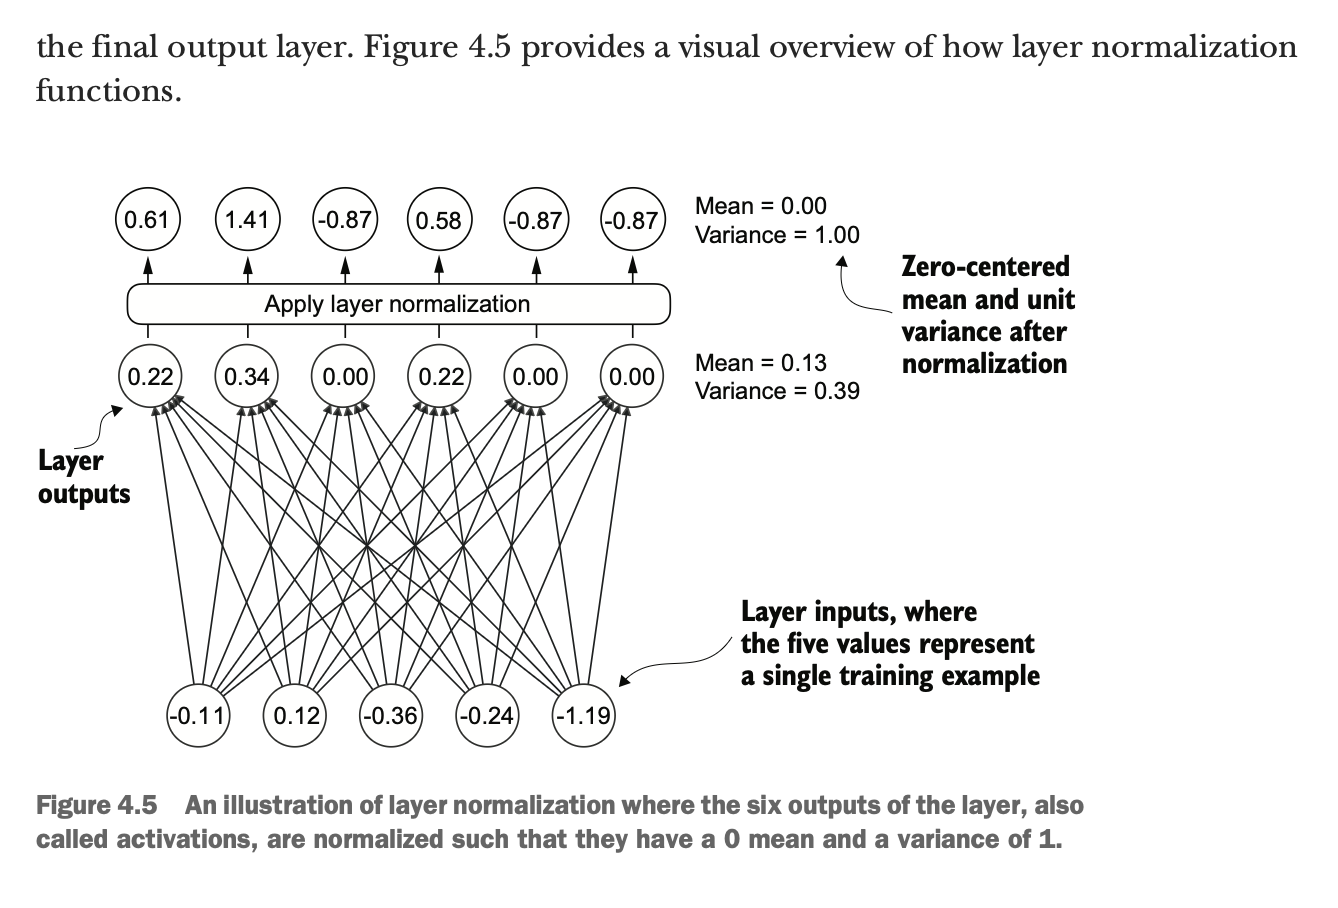


In [ ]:
import torch
import torch.nn as nn

torch.manual_seed(123)

# Creates two training examples with five dimensions (features) each
batch_example = torch.randn(2, 5)
layer = nn.Sequential(nn.Linear(5, 6), nn.ReLU())
out = layer(batch_example)
print(out)

# ReLU thresholds negative inputs to 0,
# ensuring that a layer outputs only positive values,
# which explains why the resulting layer output
# does not contain any negative values.

tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)


In [ ]:
# Before we apply layer normalization to these outputs, let’s examine the mean and
# variance:

# keepdim=True in operations like mean or variance calculation ensures
# that the
# output tensor retains the same number of dimensions
# as the input tensor, even though
# the operation reduces the tensor along the dimension specified via dim.
mean = out.mean(dim=-1, keepdim=True)
var = out.var(dim=-1, keepdim=True)
print("\n Mean : ", mean)
print("\n Variance : ", var)


 Mean :  tensor([[0.1324],
        [0.2170]], grad_fn=<MeanBackward1>)

 Variance :  tensor([[0.0231],
        [0.0398]], grad_fn=<VarBackward0>)


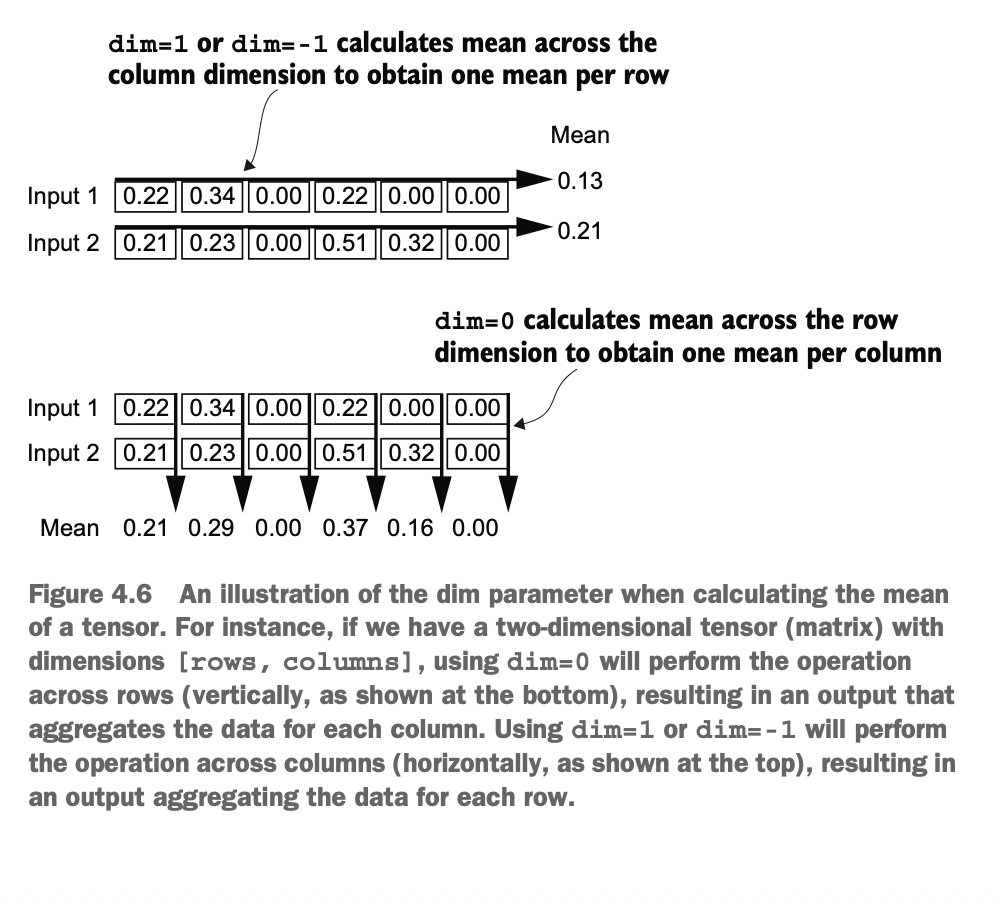


In [ ]:
# Next, let’s apply layer normalization to the layer outputs
# we obtained earlier.
# The operation consists of subtracting the mean
# and dividing by the square root of the vari-
# ance (also known as the standard deviation):

out_norm = (out - mean) / torch.sqrt(var)
mean = out_norm.mean(dim=-1, keepdim=True)
var = out_norm.var(dim=-1, keepdim=True)
print("Normalized layer outputs:\n", out_norm)
print("Mean:\n", mean)
print("Variance:\n", var)

# To improve readability, we can also turn off the
# scientific notation when printing
# tensor values by setting sci_mode to False:
torch.set_printoptions(sci_mode=False)
print("Mean:\n", mean)
print("Variance:\n", var)

In [10]:
class LayerNorm(nn.Module):

    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)

        return self.scale * norm_x + self.shift


ln = LayerNorm(emb_dim=5)
out_ln = ln(batch_example)
mean=out_ln.mean(dim=-1,keepdim=True)
var=out_ln.var(dim=-1,unbiased=False,keepdim=True)

print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[-0.0000],
        [ 0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


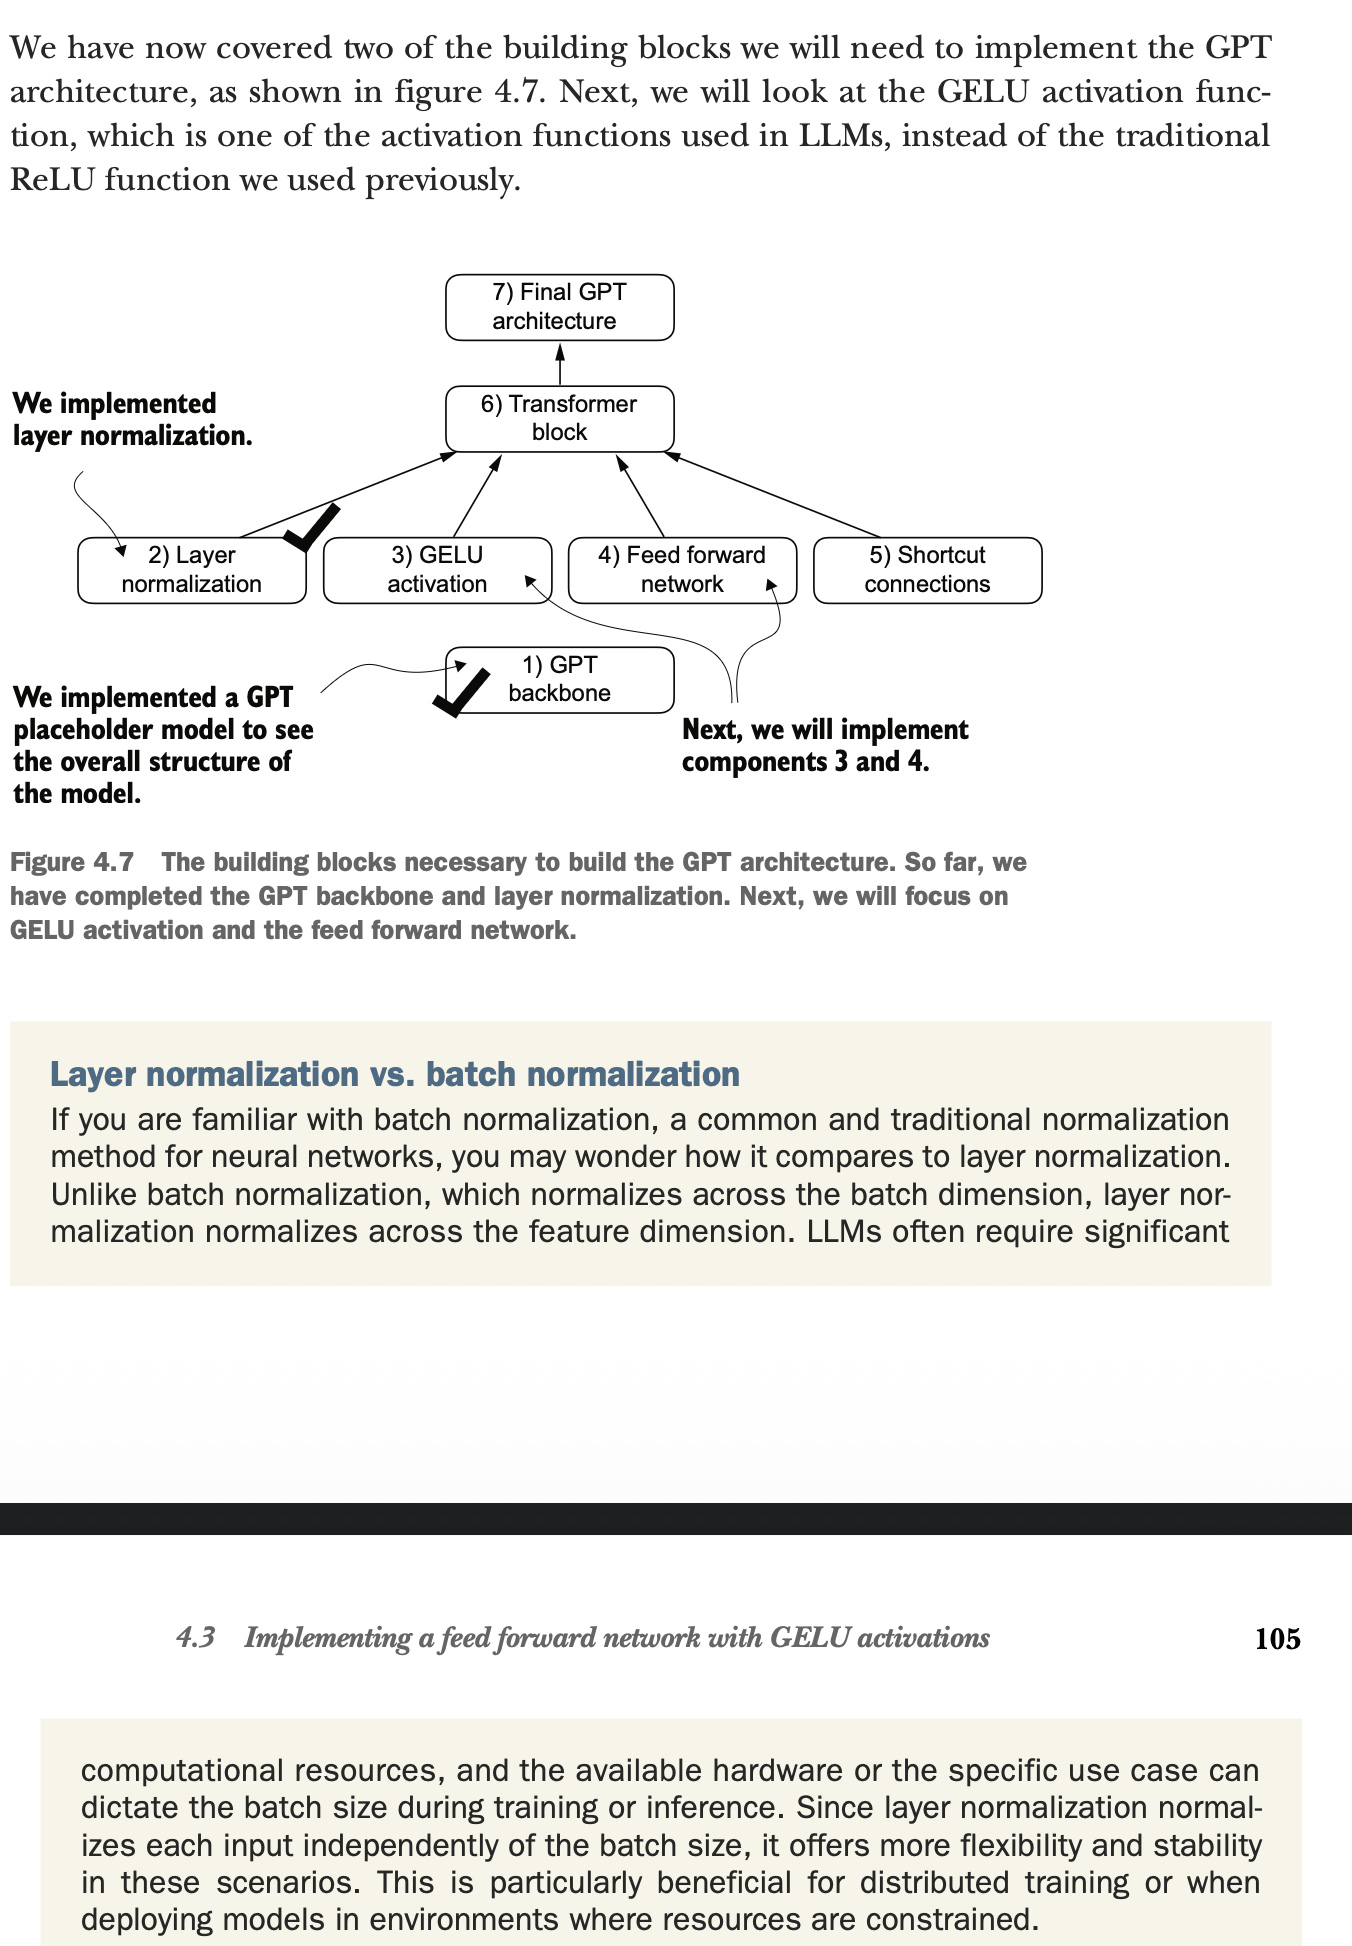

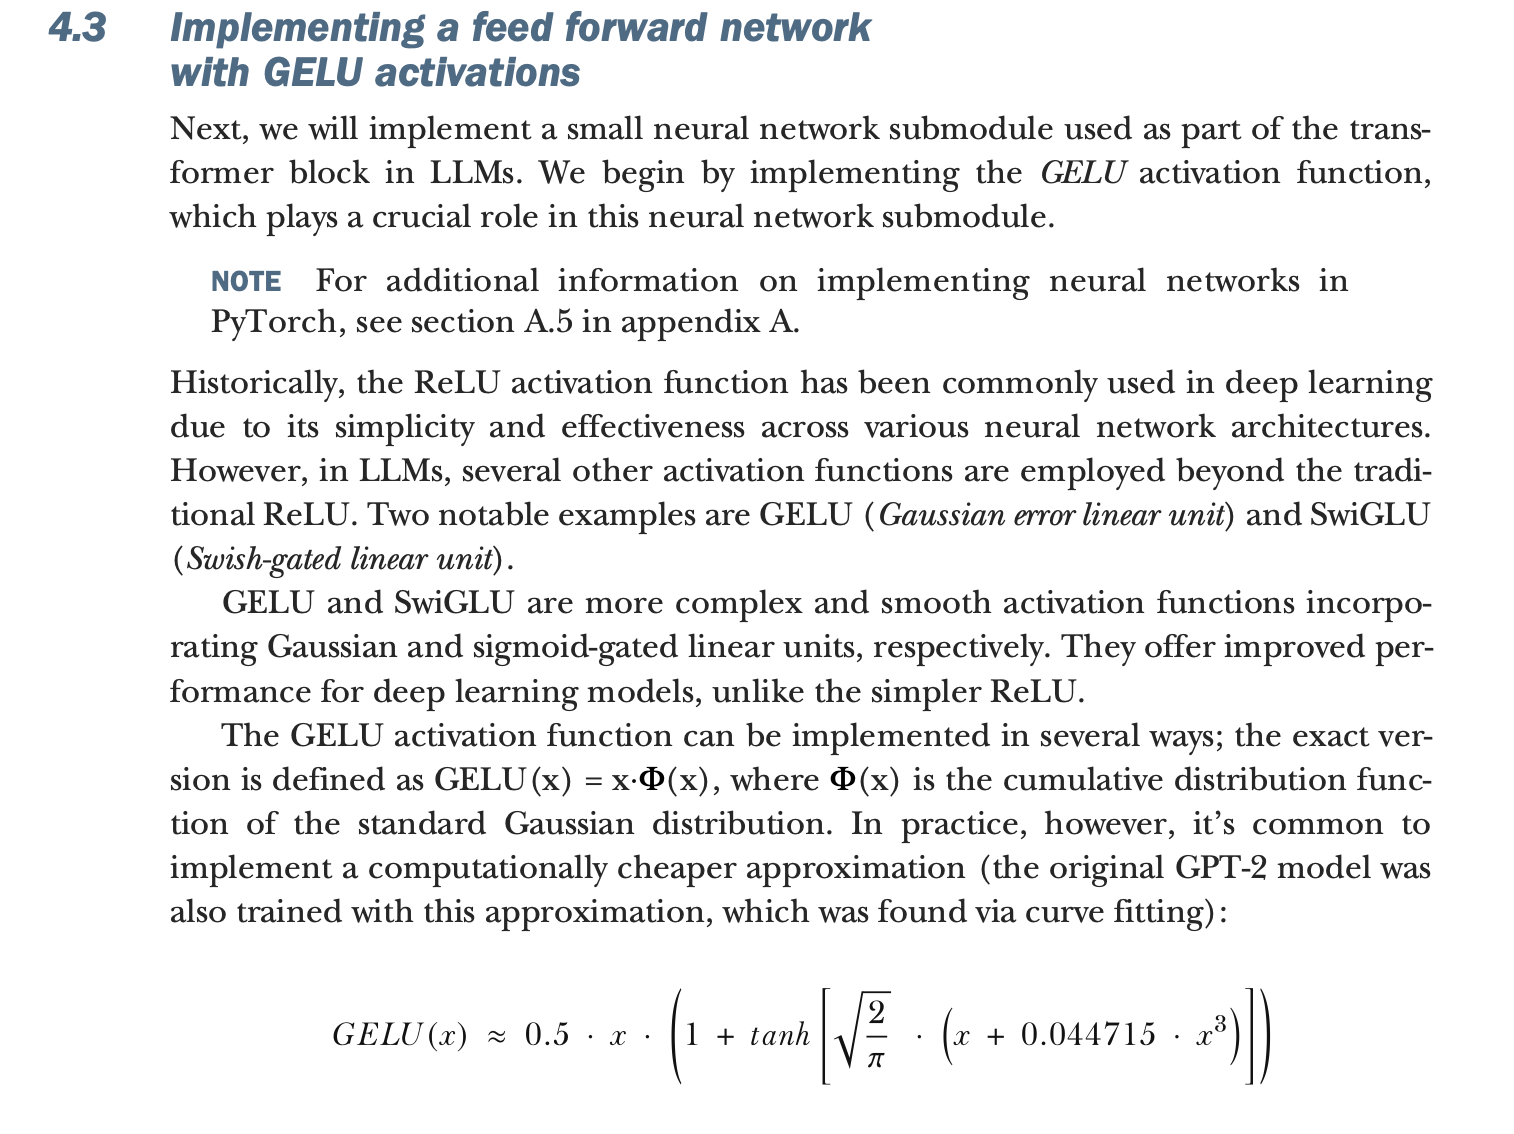

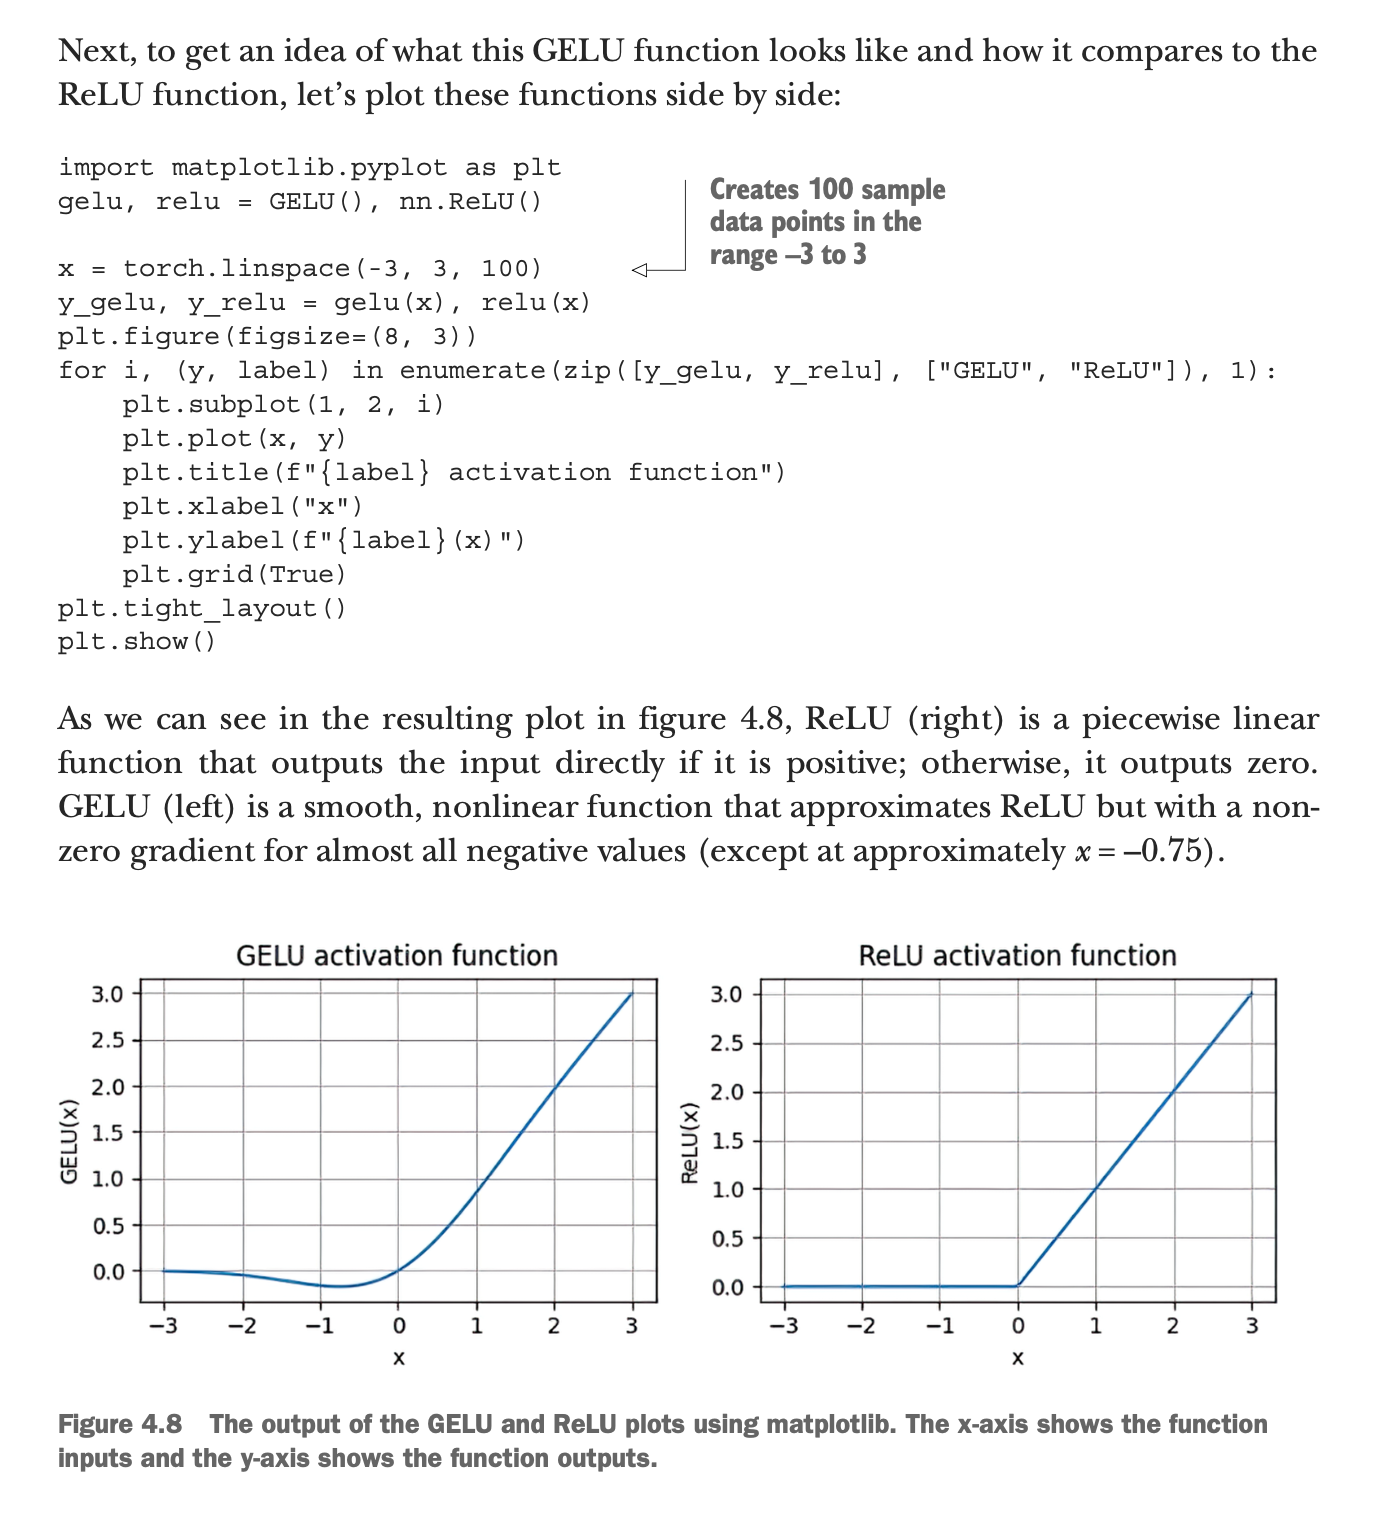

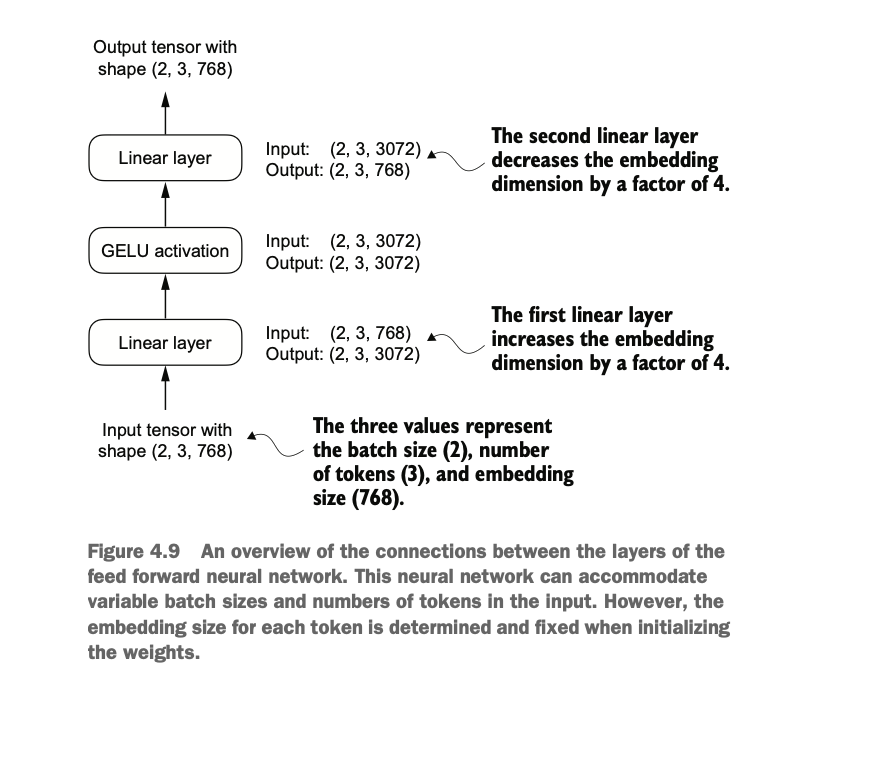

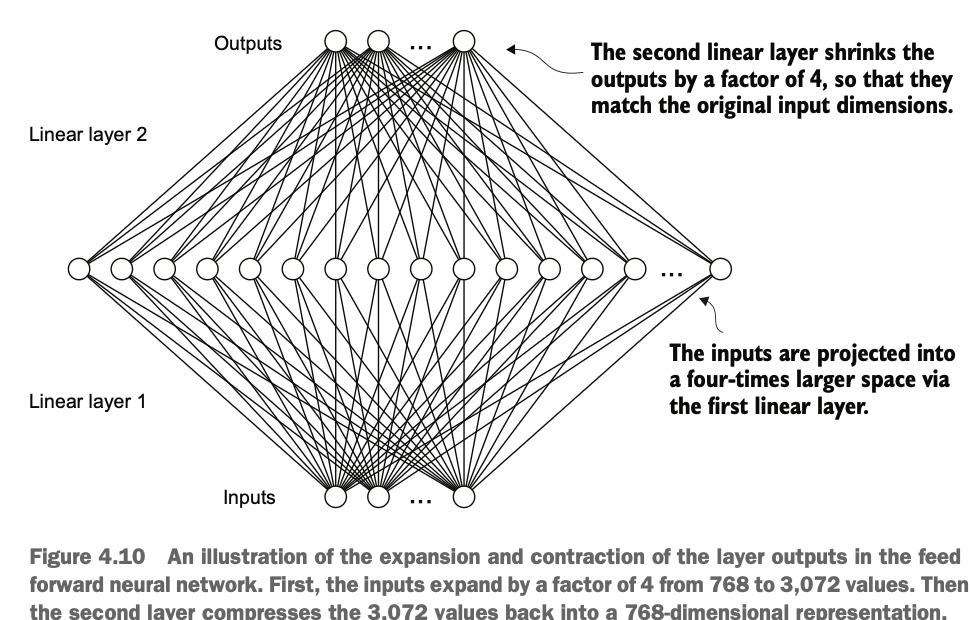

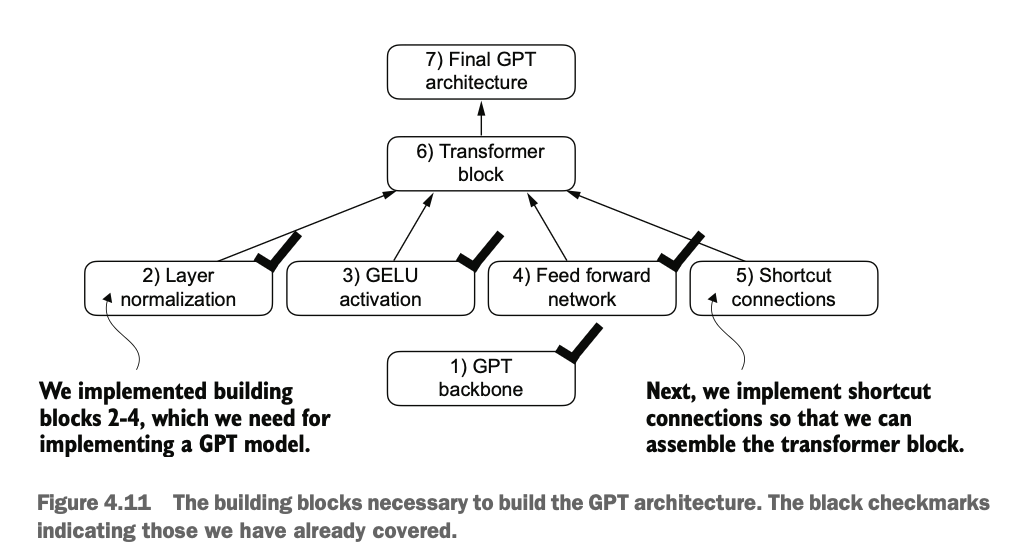

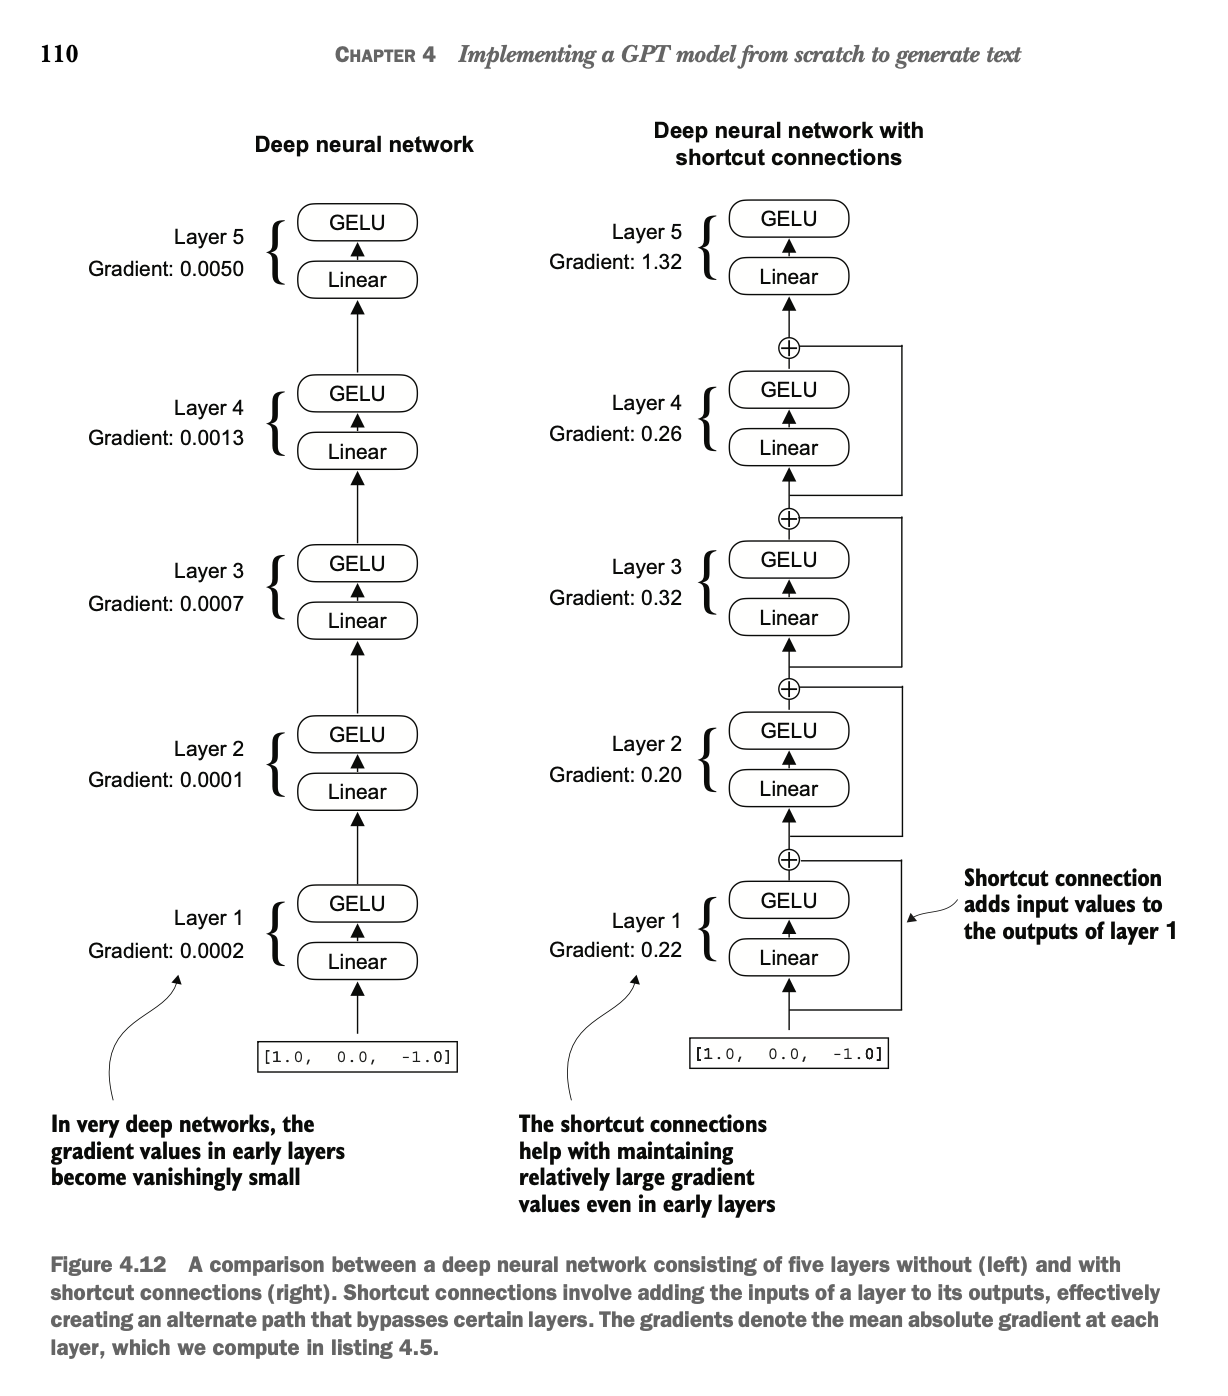